In [54]:
print("radha")

radha


In [55]:
import os
from dotenv import load_dotenv
from langchain_groq import ChatGroq
from langgraph.graph import StateGraph,START,END
from typing import TypedDict
load_dotenv()
groq_api_key = os.getenv("GROQ_API_KEY")
llm = ChatGroq(
    model="openai/gpt-oss-20b",
    groq_api_key=groq_api_key,
)

In [56]:
class BlogState(TypedDict):
    topic:str
    outline:str
    content:str
    evaluate:int

In [57]:
def outline_gen(state:BlogState)->BlogState:
    prompt=f"Generate a detailed outline for a blog post on the topic: {state['topic']}"
    response = llm.invoke(prompt)
    state['outline']=response.content
    return state

In [58]:
def content_gen(state:BlogState)->BlogState:
    prompt=f"Generate a detailed blog post based on the following outline: {state['outline']}"
    response = llm.invoke(prompt)
    state['content']=response.content
    return state

In [59]:
def evaluate_content(state:BlogState)->BlogState:
    prompt=f"Evaluate the following blog post by giving a number (1-10) only output a number based on the quality of content on the basis of the outline {state['outline']}: {state['content']}"
    response = llm.invoke(prompt)
    state['evaluate']=int(response.content.strip())
    return state

In [60]:
graph=StateGraph(BlogState)

In [61]:
graph.add_node("outline_gen",outline_gen)
graph.add_node("content_gen",content_gen)
graph.add_node("evaluate_content",evaluate_content)

graph.add_edge(START,"outline_gen")
graph.add_edge("outline_gen","content_gen")
graph.add_edge("content_gen","evaluate_content")
graph.add_edge("evaluate_content",END)

workflow=graph.compile()

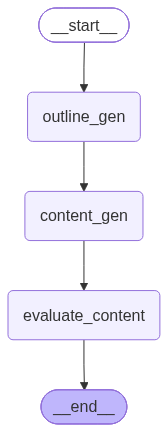

In [62]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())

In [63]:
output_state=workflow.invoke({"topic": "Impact of Artificial Intelligence in India"})

In [64]:
from rich.console import Console
from rich.markdown import Markdown

console = Console()

In [65]:

content = output_state["content"]

console.print(Markdown(content))

with open("01-promptChaining.md", "w", encoding="utf-8") as f:
    f.write(content)

The Impact of Artificial Intelligence in India: Opportunities, Challenges, and the Road Ahead           

▌ “India’s AI market is projected to hit ₹1.5 trillion by 2025 – a figure that dwarfs the country’s entire IT    
▌ services export.” – Economic Times, 2023                                                                       

-------------------------------------------------------------------------------------------------------------------

1. Introduction                                                                                                    

Hook                                                                                                               

By the end of 2024, India’s AI ecosystem is expected to contribute ₹1.5 trillion (≈US$20 billion) to the national  
economy, eclipsing the entire IT services export of ₹1.6 trillion in 2022. That’s a 10‑year jump that speaks       
volumes about the speed at which AI is becoming a national priority.                                               

Why This Matters                                                                                                   

 • Policy makers: Need to craft regulations that balance innovation with societal safeguards.                      
 • Entrepreneurs: Identify high‑impact niches and secure funding.                                                  
 • Students: Understand the skills that will drive tomorrow’s jobs.                                                
 • General audience: Grasp how AI is reshaping everyday life, from healthcare to agriculture.                      

What You’ll Learn                                                                                                  

 1 A quick snapshot of India’s AI journey.                                                                         
 2 Economic, sector‑specific, and social impacts.                                                                  
 3 The regulatory landscape and the hurdles to mainstream adoption.                                                
 4 Real‑world success stories.                                                                                     
 5 The road ahead and actionable take‑aways.                                                                       

-------------------------------------------------------------------------------------------------------------------

2. AI in India: A Quick Snapshot                                                                                   

                                                                                                                   
 Aspect              Highlights                                                                                    
 ───────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
 Historical Context  • Early AI labs at IIT Bombay (1970s) and IIT Delhi (1980s). • National AI Strategy 2021 – a  
                     5‑year roadmap.                                                                               
 Current Landscape   • 1,200+ AI startups; 14 unicorns (Haptik, Niki.ai, SigTuple, etc.). • Adoption rates: 40% of 
                     Fortune‑500 Indian firms use AI in at least one function. • Key players: academia (IISc,      
                     IITs), industry (TCS, Infosys), government (NITI Aayog), NGOs (AI for All).                   
                                                                                                                   

▌ Infographic Idea – “AI Adoption by Sector (2024)” – pie chart showing percentages for Healthcare, Agriculture, 
▌ Finance, Manufacturing, Education, Government.                                                                 

-------------------------------------------------------------------------------------------------------------------

3. Economic Impact                                          

In [66]:
console.print(Markdown(output_state["outline"]))

Blog Post Outline                                                                                                  

Title: The Impact of Artificial Intelligence in India: Opportunities, Challenges, and the Road Ahead               

-------------------------------------------------------------------------------------------------------------------

1. Introduction                                                                                                    

 • Hook: Quick statistic or anecdote (e.g., India’s AI market projected to hit ₹1.5 trillion by 2025).             
 • Purpose of the Post: Explain why AI’s impact in India matters to readers—policy makers, entrepreneurs, students,
   or general audience.                                                                                            
 • Structure Preview: Briefly outline the sections that will follow.                                               

-------------------------------------------------------------------------------------------------------------------

2. AI in India: A Quick Snapshot                                                                                   

 • Historical Context                                                                                              
    • Early AI research in Indian Institutes of Technology (IITs) & Indian Institutes of Information Technology    
      (IIITs).                                                                                                     
    • Government initiatives (e.g., National AI Strategy 2021).                                                    
 • Current Landscape                                                                                               
    • AI startups & unicorns (e.g., Haptik, Niki.ai, SigTuple).                                                    
    • Adoption rates across sectors.                                                                               
    • Key players: academia, industry, government, NGOs.                                                           

-------------------------------------------------------------------------------------------------------------------

3. Economic Impact                                                                                                 

3.1 GDP Contribution                                                                                               

 • Estimates of AI’s contribution to GDP (e.g., 1.5–2% by 2030).                                                   
 • Comparison with other emerging technologies.                                                                    

3.2 Job Creation & Skill Development                                                                               

 • New roles: data scientists, ML engineers, AI ethicists.                                                         
 • Upskilling initiatives: NPTEL courses, Coursera/edX partnerships, government skill labs.                        

3.3 Start‑up Ecosystem & Investment                                                                                

 • VC inflows & foreign direct investment trends.                                                                  
 • Success stories of AI‑driven unicorns.                                                                          

3.4 Impact on SMEs                                                                                                 

 • AI tools for inventory management, customer segmentation, and predictive maintenance.                           

-------------------------------------------------------------------------------------------------------------------

4. Sector‑Specific Impacts                                                                                         

4.1 Healthcare                                                                                                     

 • AI in diagnostics (e.g., AI‑powe

In [68]:
output_state['evaluate']

9

In [69]:
type(output_state['evaluate'])

int